In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import dask.array as da

In [2]:
from dask.distributed import Client
client = Client(threads_per_worker = 1)

In [13]:

def global_sum(a, weights):
    return (a*weights).sum(('lat', 'lon'))

def wcumsum(ds):
    """ Properly month length weighted cumulative sum"""
    month_length = ds.time.dt.days_in_month
    csum = (ds*month_length).cumsum(dim='time')
    return csum

def annual_mean(ds):
    """ Properly month length weighted annual mean of a DataArray"""
    month_length = ds.time.dt.days_in_month
    # Eventually use weighted ??? https://github.com/pydata/xarray/issues/3937
    weights = month_length.groupby('time.year') / month_length.groupby('time.year').sum()
    ann_mean = (ds*weights).groupby('time.year').sum(dim='time',min_count=1)
    # Use the original time axis
    ann_mean = ann_mean.assign_coords({'year':ds.time.groupby('time.year').mean(dim='time')})
    return ann_mean

In [3]:
esm15_picontrol = Path('/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5/piControl/r1i1p1f1')
area = xr.open_dataset(esm15_picontrol / 'fx/areacella/gn/latest/areacella_fx_ACCESS-ESM1-5_piControl_r1i1p1f1_gn.nc').areacella

In [5]:
# fld_s00i252  CO2 3D TRACER      MASS MIXING RATIO
# fld_s03i327  CO2 TOTAL FLUX TO ATMOS   KG/M**2/S
# fld_s00i407  PRESSURE AT RHO LEVELS AFTER TS
# fld_s00i409  SURFACE PRESSURE

archive_dir = Path('/g/data/jq44/access-nri/access-esm1p6/global/esm-historical/r1i1p1f1/2026.06.12')

co2_flux = xr.open_mfdataset(archive_dir.glob('output*/atmosphere/access-esm1p6.um7p3.2d.fld_s03i327.1mon.mean.*.nc'),
                parallel=True, data_vars='minimal', coords='minimal', compat='override', decode_timedelta=False).fld_s03i327
co2_mmr = xr.open_mfdataset(archive_dir.glob('output*/atmosphere/access-esm1p6.um7p3.3d.fld_s00i252.1mon.mean.*.nc'),
                parallel=True, data_vars='minimal', coords='minimal', compat='override', decode_timedelta=False).fld_s00i252
p_rho = xr.open_mfdataset(archive_dir.glob('output*/atmosphere/access-esm1p6.um7p3.3d.fld_s00i407.1mon.mean.*.nc'),
                parallel=True, data_vars='minimal', coords='minimal', compat='override', decode_timedelta=False).fld_s00i407
ps = xr.open_mfdataset(archive_dir.glob('output*/atmosphere/access-esm1p6.um7p3.2d.fld_s00i409.1mon.mean.*.nc'),
                parallel=True, data_vars='minimal', coords='minimal', compat='override', decode_timedelta=False).fld_s00i409


In [6]:
# From atmosphere/UKCA/ukca_constants.F90
c_co2 = 1.5188  # Factor for converting between mmr and vmr
grav = 9.806

nt, nlat, nlon = ps.shape
# Add a zero level at the top so that differences work
top = da.zeros((nt,1,nlat,nlon))
tmp = da.concatenate([p_rho, top], axis=1)
# Layer pressure thicknesses
dp = tmp[:,:-1] - tmp[:,1:]
# Lowest rho level is between surface and lowest theta, so add on the missing part
dp[:,0] += ps - p_rho[:,0]

co2_mass = ((co2_mmr*dp).sum('model_theta_level_number')).compute()
co2_mass_g = global_sum(co2_mass, area).compute()
co2_ppmv = (1e6 / c_co2 * co2_mass_g / global_sum(ps, area)).compute()
co2_mass_g /= grav  # Convert to kg


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 441.84 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Text(0, 0.5, 'ppmv')

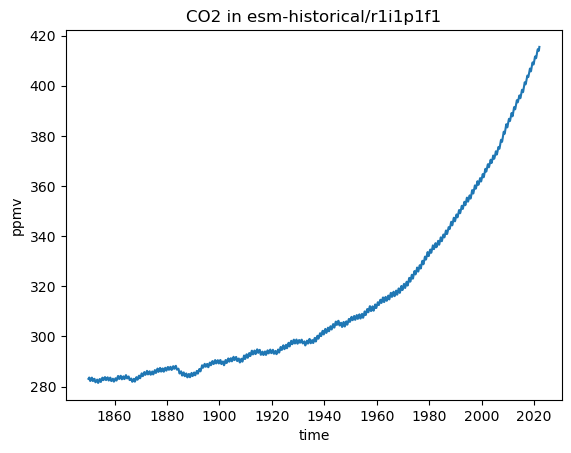

In [7]:
fig, axes = plt.subplots()
co2_ppmv.plot()
axes.set_title('CO2 in esm-historical/r1i1p1f1')
axes.set_ylabel('ppmv')

In [9]:
# Cumulative flux in kg/month
cumflux = wcumsum(global_sum(co2_flux, area)).compute() * 86400

In [10]:
# Estimate an initial Jan 1 CO2 by extrapolating the Jan and Feb means.
# Should really be calculated from the restart file
co2_mass_0 = co2_mass_g[0] - 0.5*(co2_mass_g[1]-co2_mass_g[0])

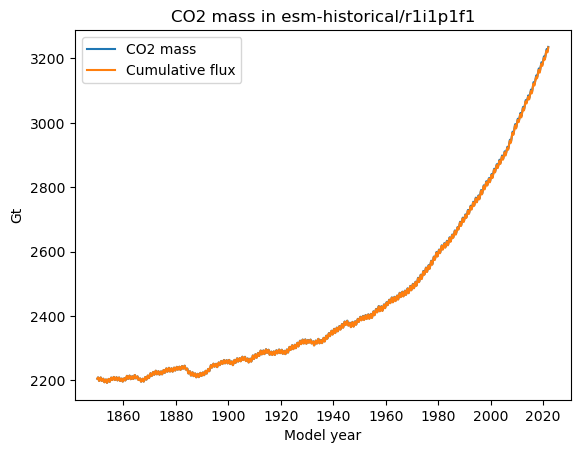

In [11]:
# Slight mismatch because co2_mass is monthly average and cumflux is end of month
fig, axes = plt.subplots()
(1e-12*co2_mass_g).plot(label='CO2 mass')
(1e-12*(co2_mass_0 + cumflux)).plot(label='Cumulative flux')
axes.set_title('CO2 mass in esm-historical/r1i1p1f1')
axes.set_ylabel('Gt')
axes.set_xlabel('Model year')
axes.legend()

In [15]:
totflux = annual_mean(global_sum(co2_flux, area)).compute()

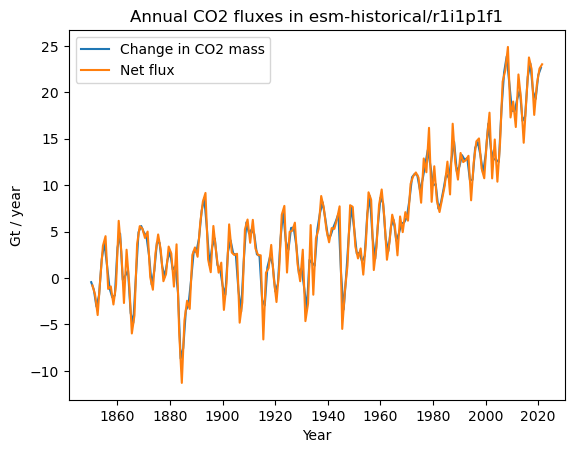

In [16]:
fig, axes = plt.subplots()
scale = 365 * 86400 * 1e-12 # kg/s to Gt/year
# Use differences between Jan means as approx differences over year
(scale*co2_mass_g[::12].differentiate('time', datetime_unit='s')).plot(label='Change in CO2 mass')
(scale*totflux).plot(label='Net flux')
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('Annual CO2 fluxes in esm-historical/r1i1p1f1')
axes.legend()
